# Case file 3 · The Profile Theory: how many bits is a shape?

<a href="https://colab.research.google.com/github/umanets/pixelsprite/blob/main/learn/03_bits.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A 16×16 silhouette has 256 yes/no pixels, so you could write it down with 256 bits.
But real shapes are not random, so they should need far fewer. How few?
We measure it, then build a simple generator from row statistics and watch it fail in an instructive way.

**Time:** about 1 minute. **You will learn:** bits and probability (−log₂ p), entropy, run-length "profiles",
a Markov chain, and why it draws shapes with thin waists.

In [1]:
try:
    import pixelsprite
except ImportError:
    %pip -q install "pixelsprite[learn] @ git+https://github.com/umanets/pixelsprite"
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
import math
from collections import Counter, defaultdict
import numpy as np
from IPython.display import display
from pixelsprite import sheet, mask_rgba
from pixelsprite.data import load_shard

sprites = load_shard(n=20000, seed=0)
masks = sprites.mask
print(len(masks), "silhouettes")

20000 silhouettes


## 1. Bits from probability
If something happens with probability *p*, writing down that it happened costs **−log₂ p bits**.
A fair coin flip: p = ½ → 1 bit. A 1-in-8 event: 3 bits. A sure thing: 0 bits.

In [3]:
for p in (1/2, 1/8, 1/256, 0.9, 0.99):
    print(f"p = {p:<8.4g} -> {-math.log2(p):6.2f} bits")

p = 0.5      ->   1.00 bits
p = 0.125    ->   3.00 bits
p = 0.003906 ->   8.00 bits
p = 0.9      ->   0.15 bits
p = 0.99     ->   0.01 bits


## 2. Rows as runs
Walk along one row: solid pixels come in **runs** (unbroken stretches). If every row has at most one run,
the whole shape is just a list of (start, end) pairs, one per row. We call that a **profile**.

In [4]:
def runs(row):
    """List of (start, end) of solid stretches in one row (end is exclusive)."""
    out, start = [], None
    for x, v in enumerate(list(row) + [False]):
        if v and start is None:
            start = x
        if not v and start is not None:
            out.append((start, x)); start = None
    return out

max_runs = np.array([max(len(runs(r)) for r in m) for m in masks])
print("share of shapes where every row is one run (a profile):", round(100 * np.mean(max_runs <= 1), 1), "%")
print("rows with 2+ runs exist in", round(100 * np.mean(max_runs >= 2), 1), "% of shapes")

share of shapes where every row is one run (a profile): 47.9 %
rows with 2+ runs exist in 52.1 % of shapes


## 3. Entropy: the average number of bits
If outcomes have probabilities p₁, p₂, …, the average cost is the **entropy** H = Σ pᵢ · (−log₂ pᵢ).
We estimate how many bits a profile row costs by counting how often each (start, end) pair appears.

In [5]:
profiles = [[runs(r)[0] if runs(r) else None for r in m] for m, k in zip(masks, max_runs) if k <= 1]
counts = Counter(pair for prof in profiles for pair in prof)
total = sum(counts.values())
H = sum(-c / total * math.log2(c / total) for c in counts.values())
print(f"{len(counts)} different row states; entropy {H:.2f} bits per row -> about {16 * H:.0f} bits per shape (vs 256)")

136 different row states; entropy 5.11 bits per row -> about 82 bits per shape (vs 256)


## 4. Smarter: rows depend on the row above (a Markov chain)
A row usually looks like the row above it. A **Markov chain** stores, for every row state, how often each next
state follows. That makes each row cheaper, and it can also *generate* new shapes: start with a first row, then
keep drawing "what usually comes next" until it says STOP.

In [6]:
STOP = "stop"
trans = defaultdict(Counter)
first = Counter()
for prof in profiles:
    rows_ = [p for p in prof if p is not None]           # the solid rows, top to bottom
    first[rows_[0]] += 1
    for a, b in zip(rows_, rows_[1:] + [STOP]):
        trans[a][b] += 1

bits = []
for prof in profiles:
    rows_ = [p for p in prof if p is not None]
    b = -math.log2(first[rows_[0]] / sum(first.values()))
    for a, nxt in zip(rows_, rows_[1:] + [STOP]):
        b += -math.log2(trans[a][nxt] / sum(trans[a].values()))
    bits.append(b)
print(f"Markov chain: median {np.median(bits):.1f} bits per shape")

Markov chain: median 44.4 bits per shape


## 5. Let the chain draw, and catch it lying
The chain knows "what follows this row" but **not how many rows are left**. Compare the sizes of real and
generated shapes. (The project's own chain, which modelled how both edges shift from row to row, failed in a
related way: its masks were too small, and 22% had a 1-pixel "thin waist" row against 4% of real ones.)

real profiles : median area   164 px, median height   16 rows, a 1-px row in  2.7% of shapes
Markov chain  : median area    33 px, median height    6 rows, a 1-px row in  2.8% of shapes


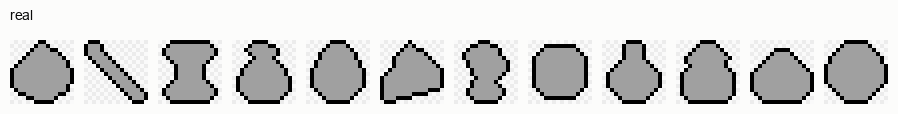

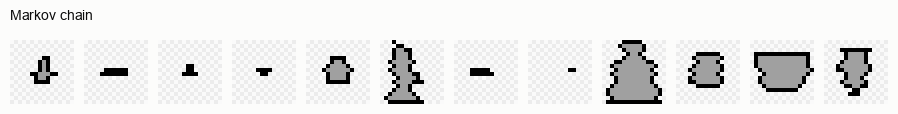

In [7]:
rng = np.random.default_rng(0)

def sample_shape():
    keys = list(first); p = np.array([first[k] for k in keys], float)
    row = keys[rng.choice(len(keys), p=p / p.sum())]
    out = [row]
    while len(out) < 16:
        opts = list(trans[row]); w = np.array([trans[row][o] for o in opts], float)
        row = opts[rng.choice(len(opts), p=w / w.sum())]
        if row == STOP:
            break
        out.append(row)
    m = np.zeros((16, 16), bool)
    top = (16 - len(out)) // 2
    for y, (s, e) in enumerate(out):
        m[top + y, s:e] = True
    return m

fake = [sample_shape() for _ in range(2000)]
real = [m for m, k in zip(masks, max_runs) if k <= 1][:2000]

def thin_waist(m):
    """Some row of the shape is only 1 pixel wide."""
    return bool((m.sum(1) == 1).any())

for name, ms in (("real profiles", real), ("Markov chain", fake)):
    print(f"{name:14}: median area {np.median([m.sum() for m in ms]):5.0f} px, median height "
          f"{np.median([m.any(1).sum() for m in ms]):4.0f} rows, a 1-px row in {100 * np.mean([thin_waist(m) for m in ms]):4.1f}% of shapes")
display(sheet([mask_rgba(m) for m in real[:12]], "real", scale=4, cols=12))
display(sheet([mask_rgba(m) for m in fake[:12]], "Markov chain", scale=4, cols=12))

## Your turn
1. Make the chain remember **two** rows (use pairs of rows as the state). Do the shapes get taller? What goes wrong?
   (Hint: with more memory there are many more states and most of them are seen only once.)
2. Count bits for symmetric shapes only: you need the axis and half the width per row. How many bits now?